# **Lab 9 - Morphological Operations**

**Objective:** Apply erosion, dilation, opening, and closing, and investigate structuring element shapes and sizes.

This solution uses the uploaded Balls.png image. Otsu thresholding with inversion makes the dark balls, numbers, and border white foreground. The image is not cropped or resized. Run the cells in order; upload Balls.png when Colab prompts, or place it beside the notebook in Jupyter.

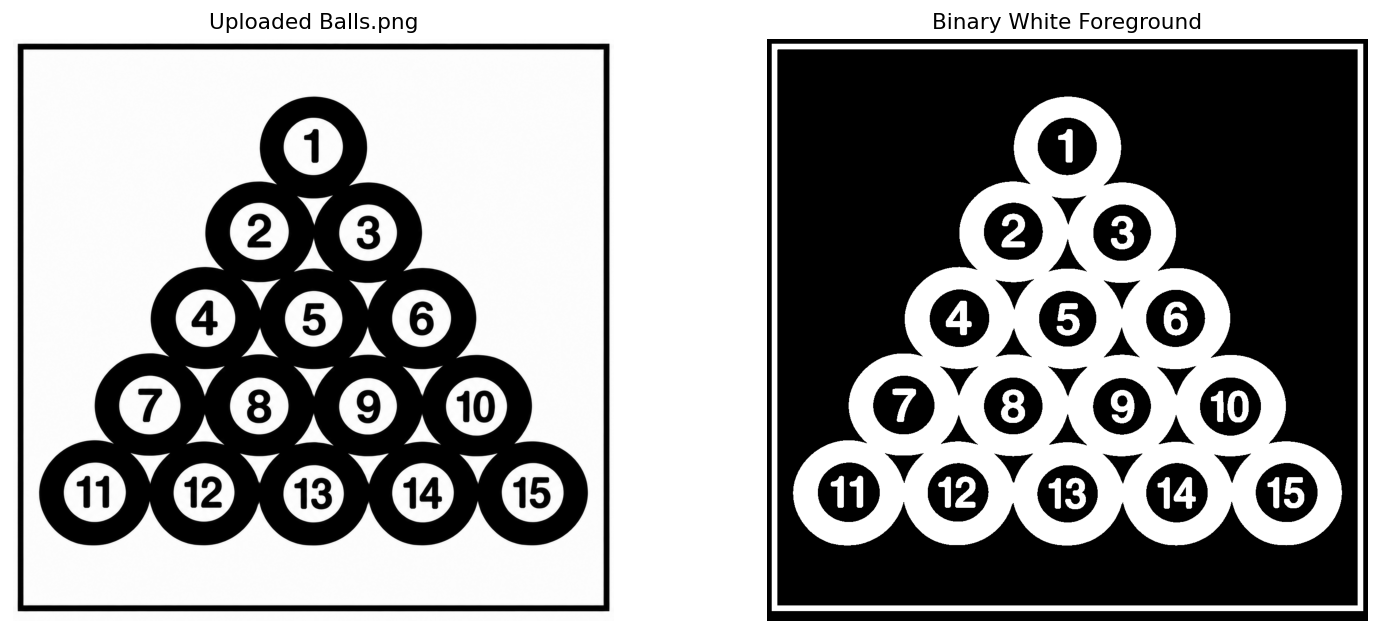

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

#(prompt for an upload if Balls.png is not present)
image_path = Path("Balls.png")
if not image_path.exists():
    from google.colab import files
    uploaded = files.upload()
    image_path = Path(next(iter(uploaded)))

img = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
if img is None:
    raise ValueError("Could not read the uploaded image.")

# Black balls become white foreground-retain the full image
_, binary = cv2.threshold(
    img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, result, title in zip(ax, [img, binary],
                           ["Uploaded Balls.png", "Binary White Foreground"]):
    a.imshow(result, cmap="gray", vmin=0, vmax=255)
    a.set_title(title)
    a.axis("off")
plt.tight_layout()
plt.show()

## **Task 1 - Erosion, Dilation, Opening, and Closing**

Use the same 5x5 square kernel with one iteration for each operation. Each operation is applied independently to the original image.

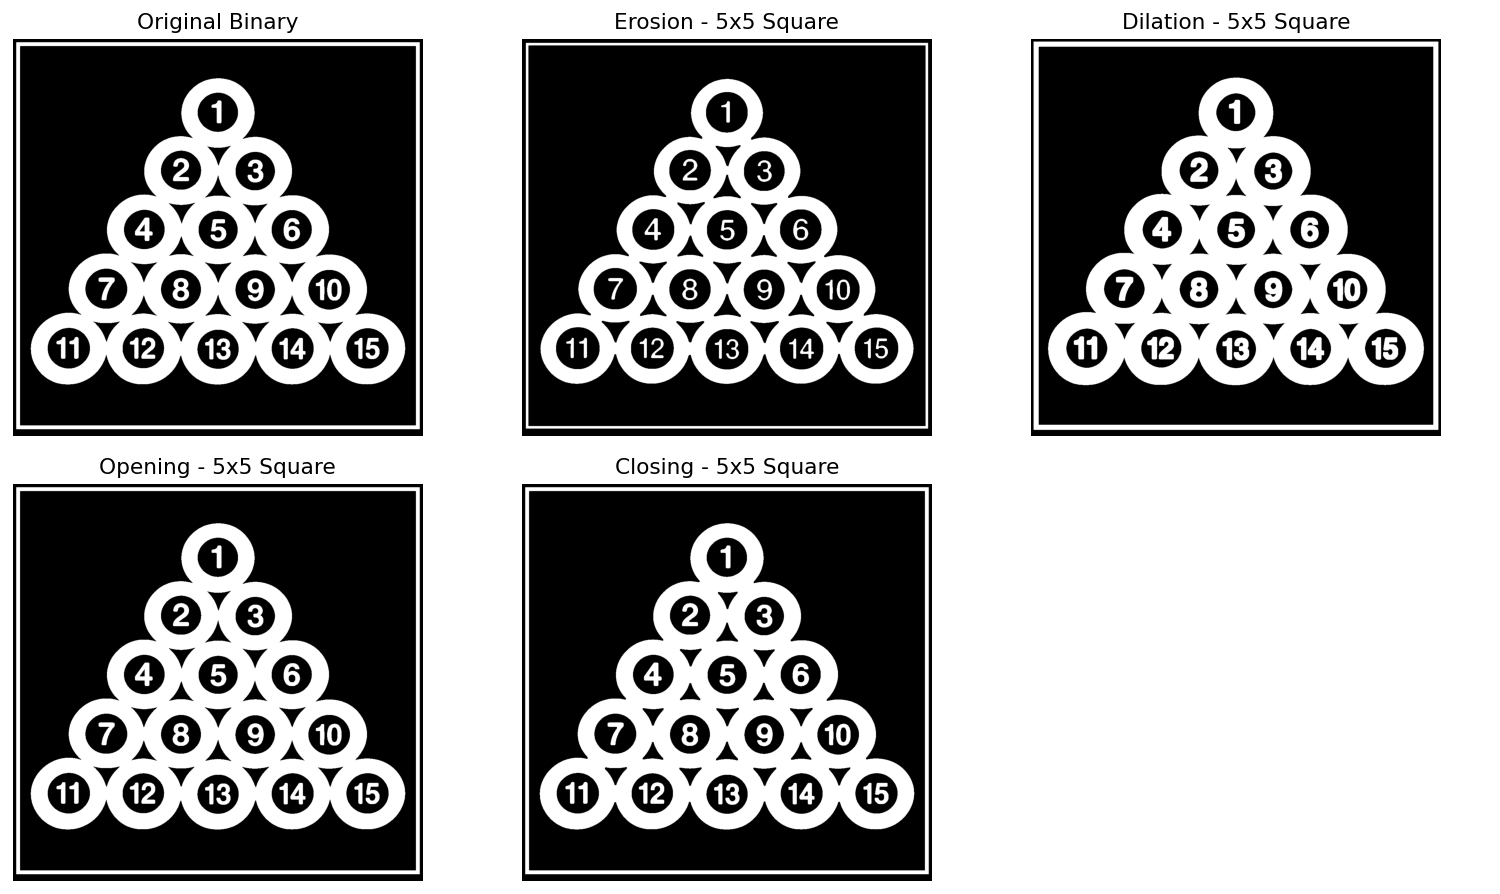

In [ ]:
kernel = np.ones((5, 5), dtype=np.uint8)

eroded = cv2.erode(binary, kernel, iterations=1)
dilated = cv2.dilate(binary, kernel, iterations=1)
opening = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)
closing = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)

fig, ax = plt.subplots(2, 3, figsize=(12, 7))
images = [binary, eroded, dilated, opening, closing]
titles = ["Original Binary", "Erosion - 5x5 Square",
          "Dilation - 5x5 Square", "Opening - 5x5 Square",
          "Closing - 5x5 Square"]
for a, image, title in zip(ax.flat, images, titles):
    a.imshow(image, cmap="gray", vmin=0, vmax=255)
    a.set_title(title)
    a.axis("off")
ax.flat[-1].axis("off")
plt.tight_layout()
plt.show()

## **Task 2 - Structuring Element Shapes and Sizes**

Compare square, cross, and ellipse kernels at 3x3, 5x5, and 7x7. The original image and the iteration count remain fixed. The following plots show the actual OpenCV kernel masks.

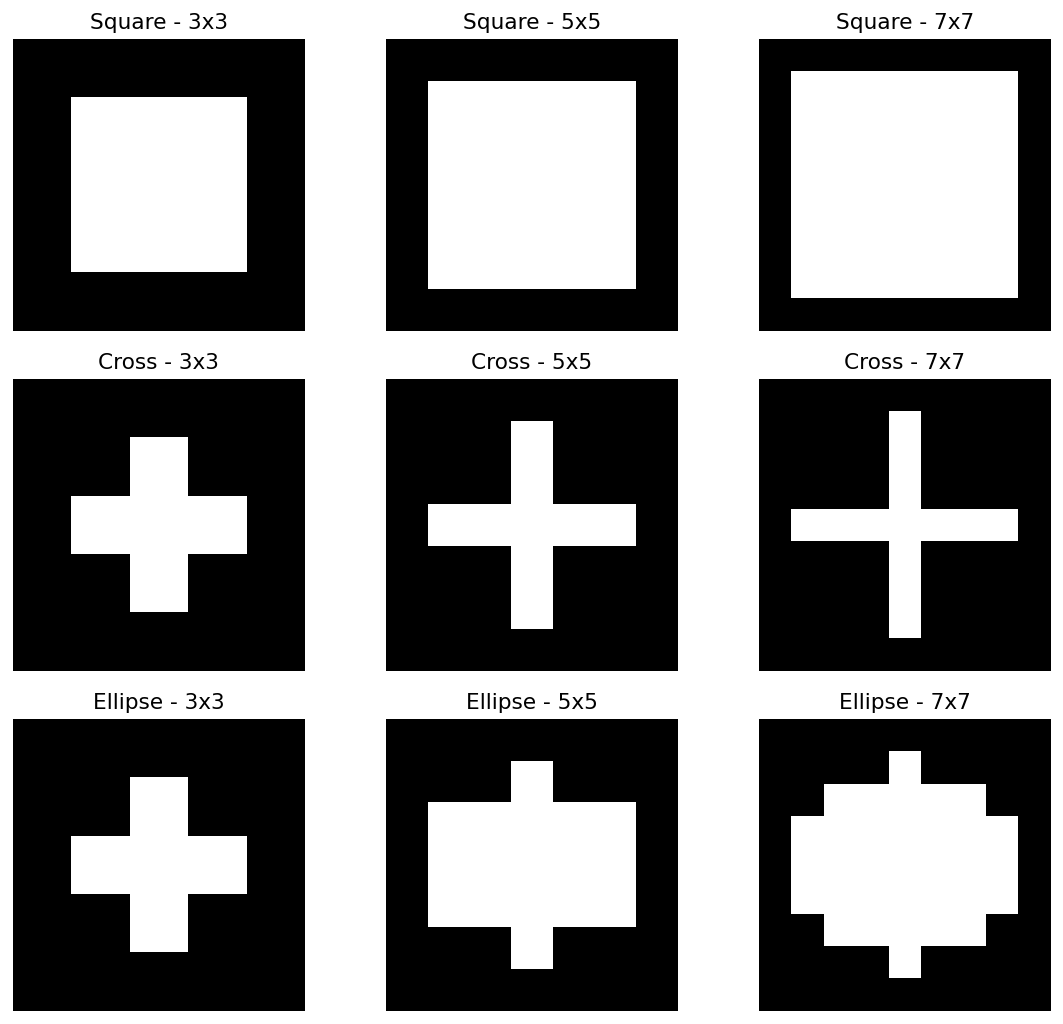

In [ ]:
shapes = {"Square": cv2.MORPH_RECT,
          "Cross": cv2.MORPH_CROSS,
          "Ellipse": cv2.MORPH_ELLIPSE}
sizes = [3, 5, 7]
kernels = {}

fig, ax = plt.subplots(3, 3, figsize=(9, 8))
for row, (name, shape) in enumerate(shapes.items()):
    for col, size in enumerate(sizes):
        element = cv2.getStructuringElement(shape, (size, size))
        kernels[(name, size)] = element
        ax[row, col].imshow(np.pad(element, 1), cmap="gray", vmin=0, vmax=1)
        ax[row, col].set_title(f"{name} - {size}x{size}")
        ax[row, col].axis("off")
plt.tight_layout()
plt.show()

### **Erosion Comparison**

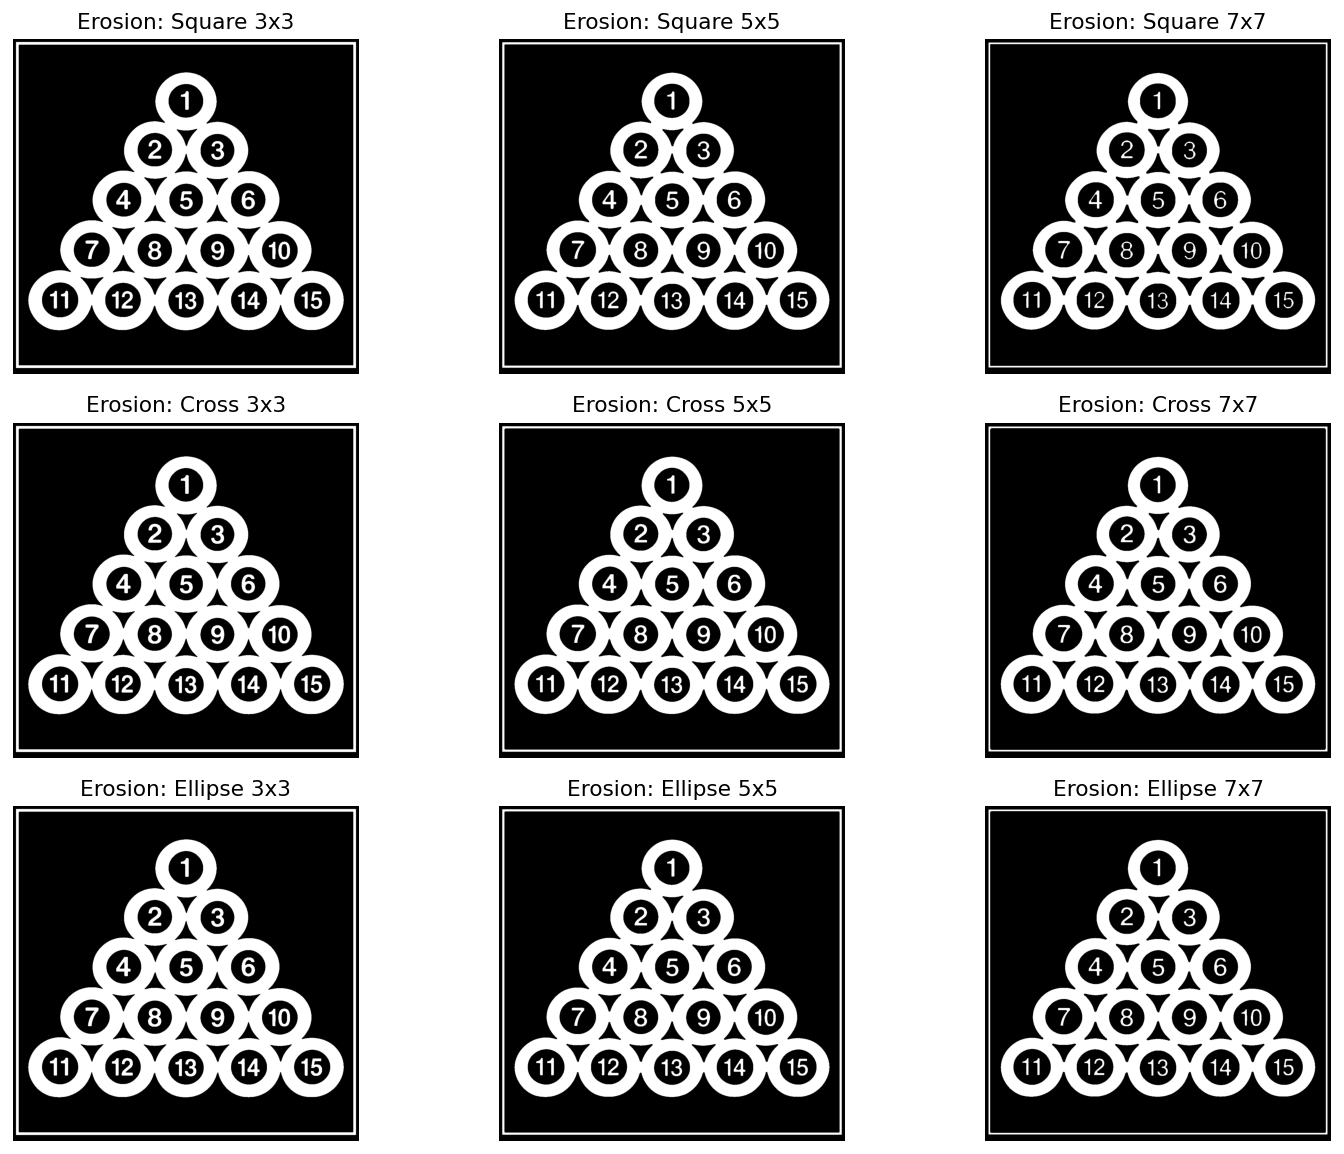

In [ ]:
erosion_results = {}
fig, ax = plt.subplots(3, 3, figsize=(12, 9))
for row, name in enumerate(shapes):
    for col, size in enumerate(sizes):
        result = cv2.erode(binary, kernels[(name, size)], iterations=1)
        erosion_results[(name, size)] = result
        ax[row, col].imshow(result, cmap="gray", vmin=0, vmax=255)
        ax[row, col].set_title(f"Erosion: {name} {size}x{size}")
        ax[row, col].axis("off")
plt.tight_layout()
plt.show()

### **Dilation Comparison**

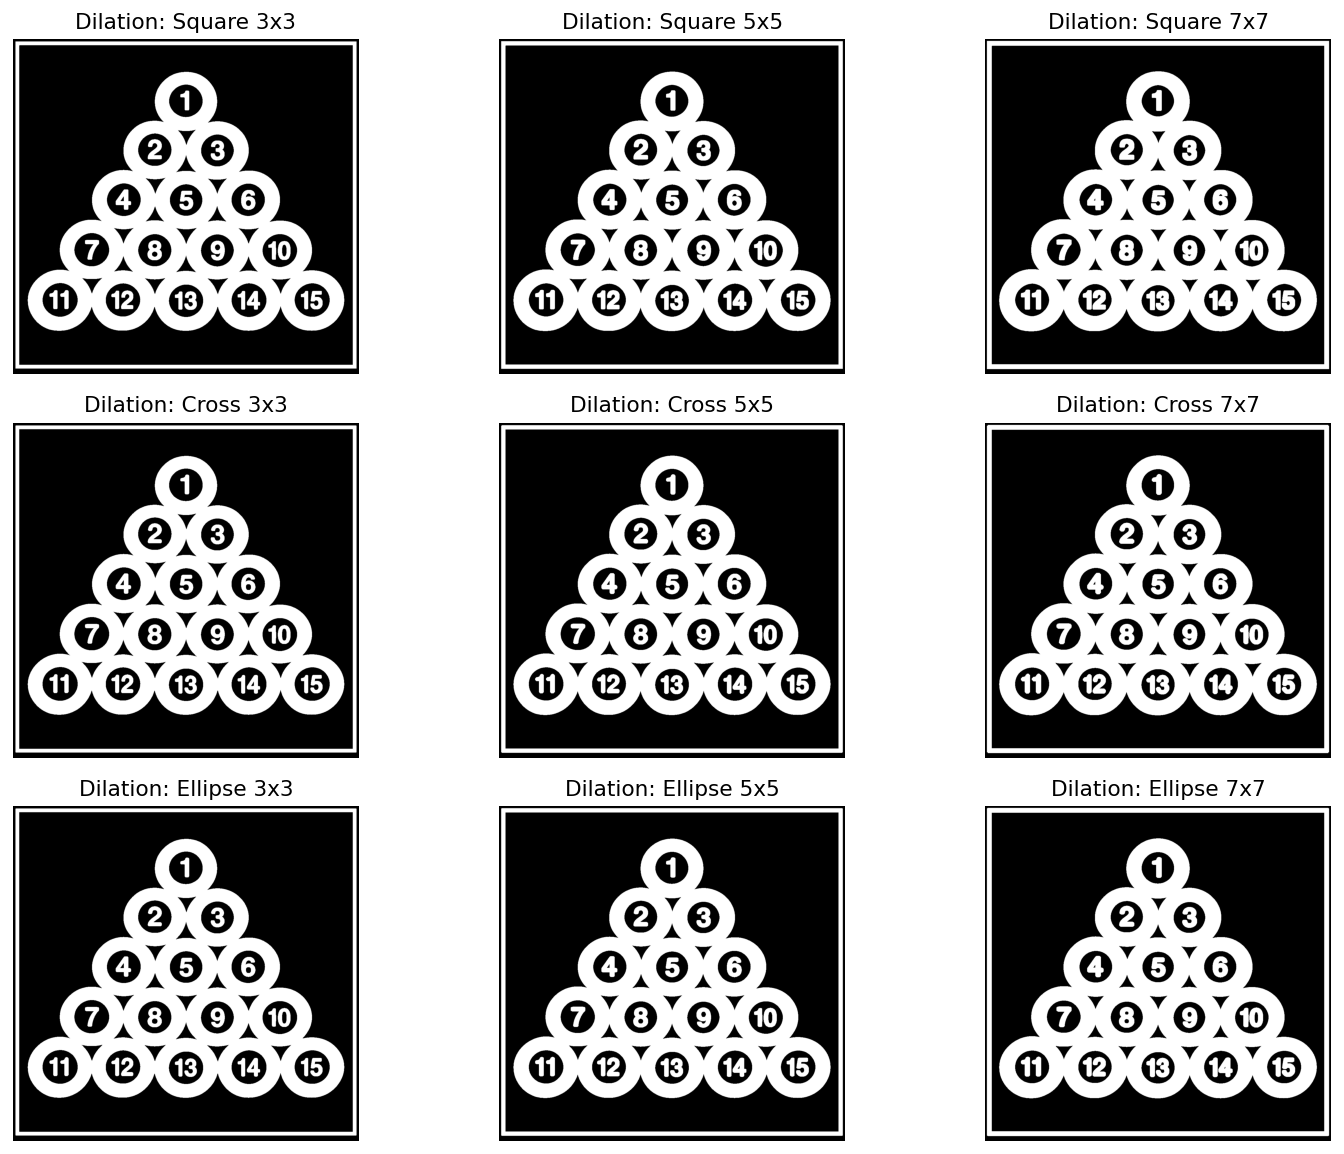

In [ ]:
dilation_results = {}
fig, ax = plt.subplots(3, 3, figsize=(12, 9))
for row, name in enumerate(shapes):
    for col, size in enumerate(sizes):
        result = cv2.dilate(binary, kernels[(name, size)], iterations=1)
        dilation_results[(name, size)] = result
        ax[row, col].imshow(result, cmap="gray", vmin=0, vmax=255)
        ax[row, col].set_title(f"Dilation: {name} {size}x{size}")
        ax[row, col].axis("off")
plt.tight_layout()
plt.show()